In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)

print("EDA environment ready!")

EDA environment ready!


In [2]:
# Load cleaned data

data_folder = Path("../data/cleaned")

skills = pd.read_csv(
    data_folder / "skills_cleaned.csv"
)

vacancies = pd.read_csv(
    data_folder / "vacancies_cleaned.csv"
)

vacancy_skills = pd.read_csv(
    data_folder / "vacancy_skills_cleaned.csv"
)

print("Skills:", skills.shape)
print("Vacancies:", vacancies.shape)
print("Vacancy-Skills:", vacancy_skills.shape)

Skills: (2033, 2)
Vacancies: (2154, 14)
Vacancy-Skills: (13032, 2)


In [3]:
# Create EDA master dataset

vacancy_skill_data = vacancy_skills.merge(
    skills,
    left_on="skill_id",
    right_on="id",
    how="left"
)

vacancy_skill_data = vacancy_skill_data.merge(
    vacancies,
    left_on="vacancy_id",
    right_on="id",
    how="left",
    suffixes=("_skill", "_vacancy")
)

print("Master dataset shape:", vacancy_skill_data.shape)

Master dataset shape: (13032, 18)


# Job Market Intelligence — Exploratory Data Analysis

## 1. Dataset Overview

This analysis explores job-market demand for Data Analyst and related
roles using vacancy, skill, company, location, and experience data.

In [4]:
total_vacancies = vacancies["id"].nunique()
vacancies_with_skills = vacancy_skills["vacancy_id"].nunique()
total_skills = skills["id"].nunique()
total_skill_mappings = len(vacancy_skills)

skill_coverage = (
    vacancies_with_skills / total_vacancies * 100
)

print("Total Vacancies:", total_vacancies)
print("Vacancies with Skills:", vacancies_with_skills)
print("Total Unique Skills:", total_skills)
print("Total Skill Mappings:", total_skill_mappings)
print("Skill Coverage:", round(skill_coverage, 2), "%")

Total Vacancies: 2154
Vacancies with Skills: 1873
Total Unique Skills: 2033
Total Skill Mappings: 13032
Skill Coverage: 86.95 %


## 2. Job Category Analysis

This section examines the distribution of Data Analyst and related
job categories in the dataset.

In [5]:
job_counts = (
    vacancies["job_category"]
    .value_counts()
)

job_counts

job_category
Data Analyst               1682
Senior Data Analyst         181
Business Data Analyst        65
Junior Data Analyst          54
Data Analyst Intern          47
Marketing Data Analyst       29
Other Analyst                19
Lead Data Analyst            18
Financial Data Analyst       18
Healthcare Data Analyst      15
Product Data Analyst          9
Market Data Analyst           7
Business Analyst              6
Reporting Analyst             4
Name: count, dtype: int64

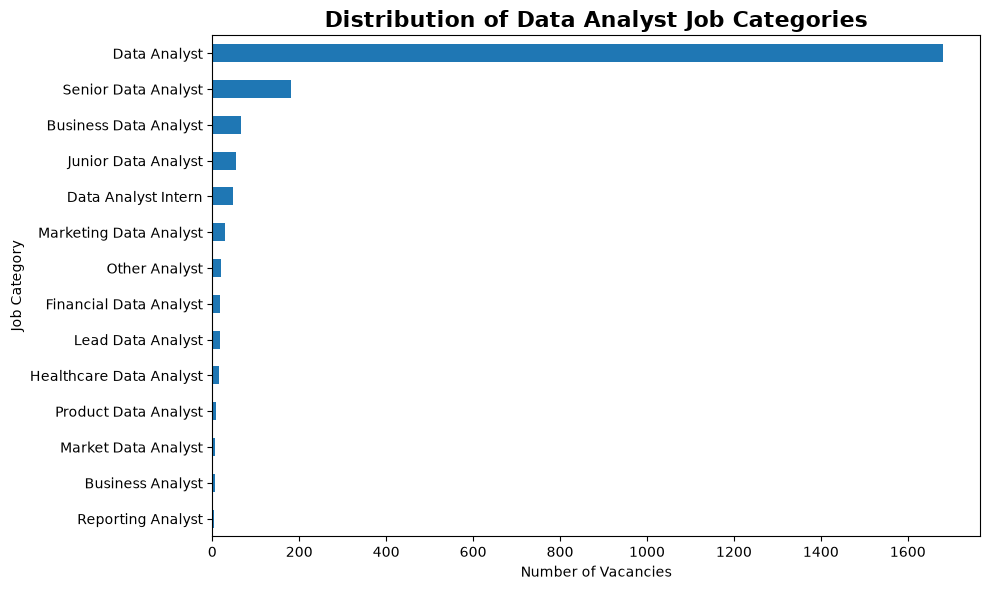

In [6]:
plt.figure(figsize=(10, 6))

job_counts.sort_values().plot(
    kind="barh"
)

plt.title(
    "Distribution of Data Analyst Job Categories",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Vacancies")
plt.ylabel("Job Category")

plt.tight_layout()
plt.show()

In [7]:
# Add percentages

job_percentage = (
    vacancies["job_category"]
    .value_counts(normalize=True)
    * 100
).round(2)

job_percentage

job_category
Data Analyst               78.09
Senior Data Analyst         8.40
Business Data Analyst       3.02
Junior Data Analyst         2.51
Data Analyst Intern         2.18
Marketing Data Analyst      1.35
Other Analyst               0.88
Lead Data Analyst           0.84
Financial Data Analyst      0.84
Healthcare Data Analyst     0.70
Product Data Analyst        0.42
Market Data Analyst         0.32
Business Analyst            0.28
Reporting Analyst           0.19
Name: proportion, dtype: float64

In [8]:
job_summary = pd.DataFrame({
    "Vacancy_Count": job_counts,
    "Percentage": job_percentage
})

job_summary

,Vacancy_Count,Percentage
job_category,,
Data Analyst,1682,78.09
Senior Data Analyst,181,8.40
Business Data Analyst,65,3.02
Junior Data Analyst,54,2.51
Data Analyst Intern,47,2.18
Marketing Data Analyst,29,1.35
Other Analyst,19,0.88
Lead Data Analyst,18,0.84
Financial Data Analyst,18,0.84


## 3. Experience Level Analysis

This section examines the experience levels requested across
Data Analyst-related vacancies.

In [9]:
experience_counts = (
    vacancies["experience_level_clean"]
    .value_counts()
)

experience_counts

experience_level_clean
Not Specified     947
Mid Level         368
Entry Level       271
Senior            229
Junior            119
Not Applicable     89
Mid-Senior         53
Lead               29
Associate          28
Unknown            16
Internship          5
Name: count, dtype: int64

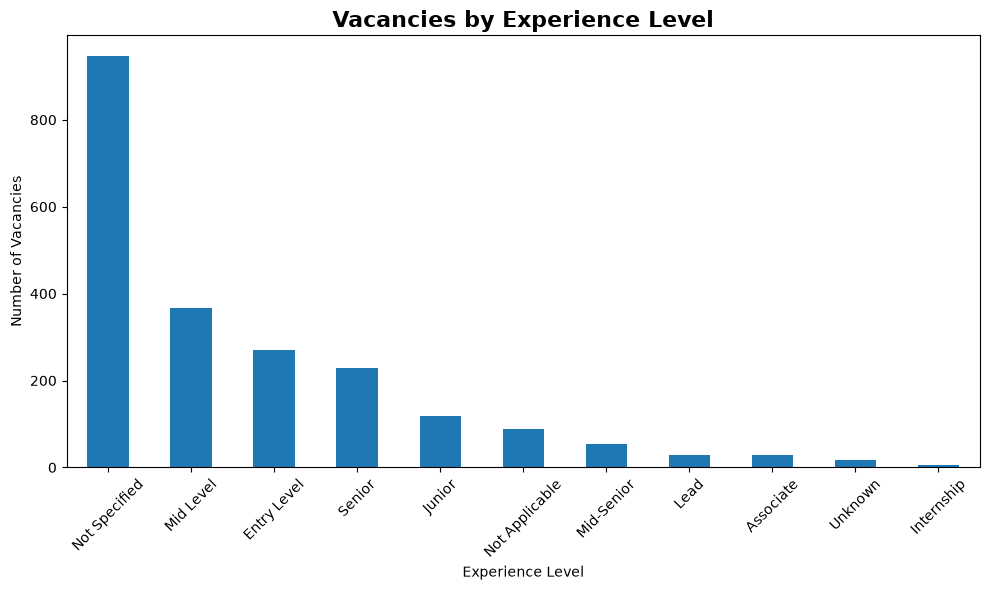

In [10]:
plt.figure(figsize=(10, 6))

experience_counts.plot(
    kind="bar"
)

plt.title(
    "Vacancies by Experience Level",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Experience Level")
plt.ylabel("Number of Vacancies")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4. Remote Job Analysis

This section examines the availability of remote and location-specific
Data Analyst opportunities.

In [11]:
location_type_counts = (
    vacancies["location_type"]
    .value_counts()
)

location_type_counts

location_type
Onsite / Location Specified    1942
Remote                          187
Unknown                          25
Name: count, dtype: int64

In [12]:
location_type_percentage = (
    vacancies["location_type"]
    .value_counts(normalize=True) * 100
).round(2)

location_type_percentage

location_type
Onsite / Location Specified    90.16
Remote                          8.68
Unknown                         1.16
Name: proportion, dtype: float64

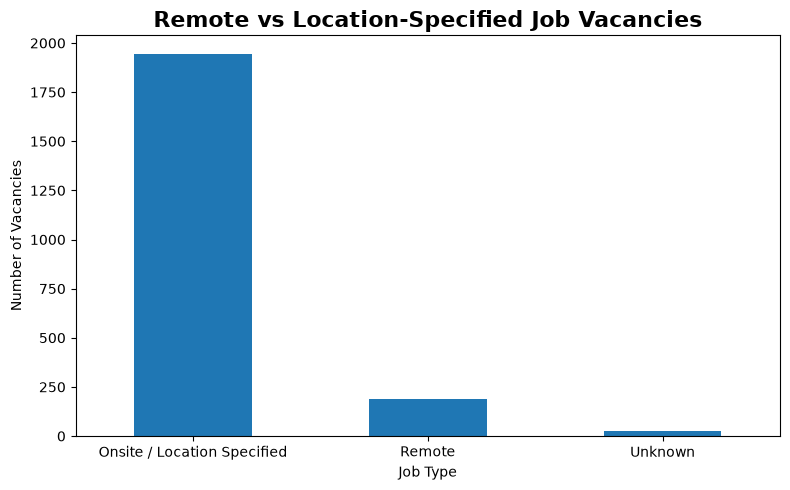

In [13]:
plt.figure(figsize=(8, 5))

location_type_counts.plot(kind="bar")

plt.title(
    "Remote vs Location-Specified Job Vacancies",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Job Type")
plt.ylabel("Number of Vacancies")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 5. Geographic Analysis

This section identifies the locations with the highest concentration
of Data Analyst opportunities.

In [14]:
top_locations = (
    vacancies["location"]
    .value_counts()
    .head(15)
)

top_locations

location
Anywhere             187
United States        154
New York, NY          67
Kuala Lumpur          47
Singapore             32
San Francisco, CA     29
Unknown               25
Austin, TX            24
India                 24
Paris, France         23
Los Angeles, CA       23
Chicago, IL           22
United Kingdom        19
Washington, DC        19
Atlanta, GA           18
Name: count, dtype: int64

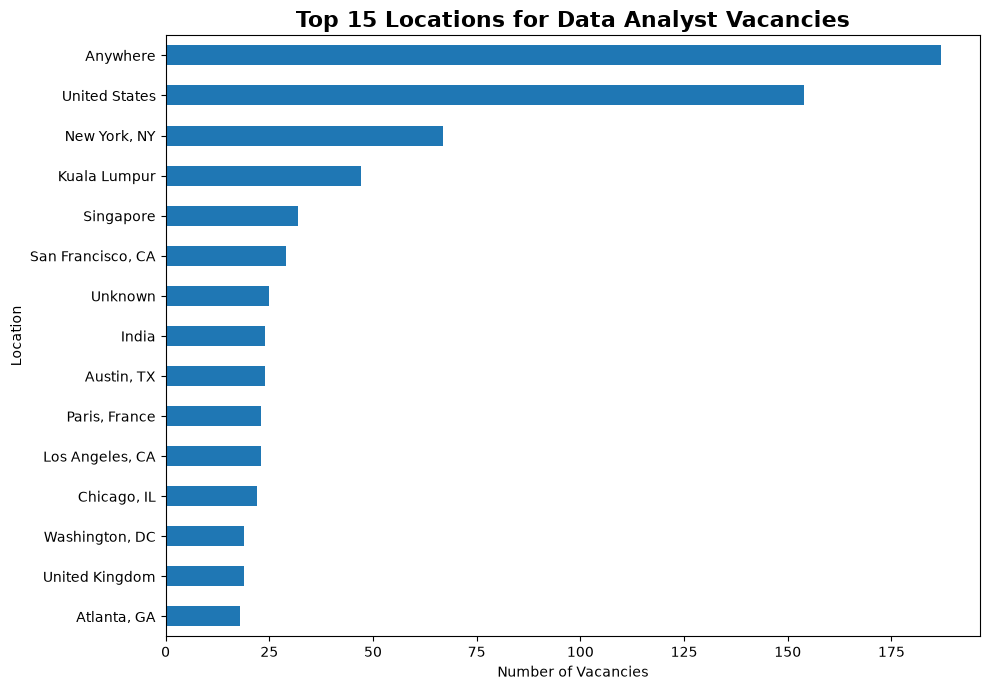

In [15]:
plt.figure(figsize=(10, 7))

top_locations.sort_values().plot(kind="barh")

plt.title(
    "Top 15 Locations for Data Analyst Vacancies",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Vacancies")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

## 6. Company Analysis

This section identifies companies appearing most frequently
in the vacancy dataset.

In [16]:
top_companies = (
    vacancies[
        vacancies["company"].notna()
        & (vacancies["company"] != "Unknown")
    ]["company"]
    .value_counts()
    .head(15)
)

top_companies

company
Upwork                26
Insight Global        18
Dice                  13
Meta                  13
EDWARD JONES          11
AARATECH              10
Turing.com             9
Corporate              8
UnitedHealth Group     8
Michael Page           8
Crossing Hurdles       7
Kforce Inc             7
Brooksource            7
Revolut                6
Microsoft              6
Name: count, dtype: int64

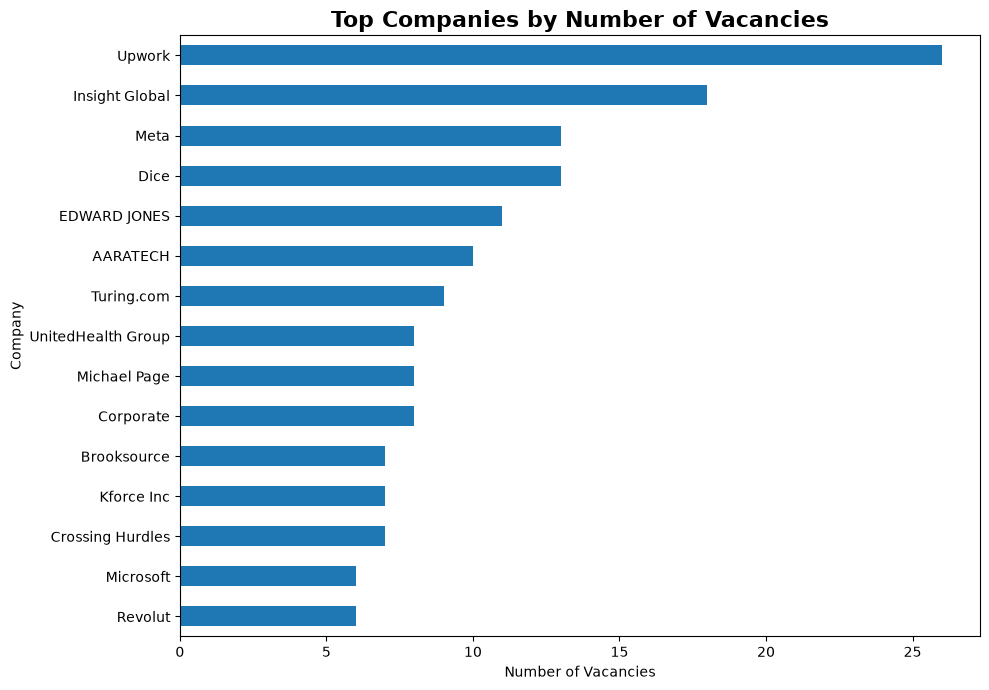

In [17]:
plt.figure(figsize=(10, 7))

top_companies.sort_values().plot(kind="barh")

plt.title(
    "Top Companies by Number of Vacancies",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Vacancies")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

## 7. In-Demand Skills Analysis

This section identifies the technical and analytical skills
most frequently requested across job vacancies.

In [18]:
top_skills = (
    vacancy_skill_data
    .groupby("name")["vacancy_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(20)
)

top_skills

name
SQL                     1298
Python                   760
Excel                    692
Tableau                  685
Power BI                 568
R                        395
Data Visualization       248
Data Analysis            207
SAS                      169
Data Modeling            166
Looker                   145
Snowflake                127
Microsoft Excel          121
Statistical Analysis     114
AWS                      111
PowerPoint               110
ETL                      110
Reporting                102
Azure                     91
Oracle                    87
Name: vacancy_id, dtype: int64

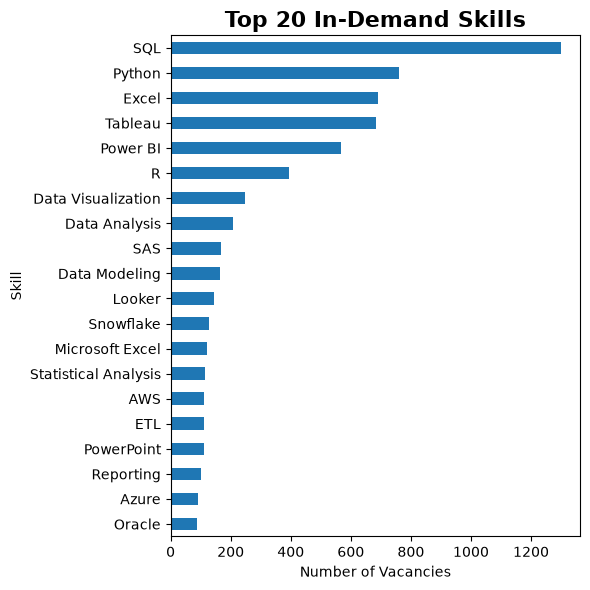

In [25]:
plt.figure(figsize=(6,6))

top_skills.sort_values().plot(kind="barh")

plt.title(
    "Top 20 In-Demand Skills",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Vacancies")
plt.ylabel("Skill")

plt.tight_layout()
plt.show()

In [20]:
# Skill Demand Percentage

skill_demand = (
    vacancy_skill_data
    .groupby("name")["vacancy_id"]
    .nunique()
    .reset_index(name="vacancy_count")
)

total_vacancies_with_skills = (
    vacancy_skill_data["vacancy_id"].nunique()
)

skill_demand["demand_percentage"] = (
    skill_demand["vacancy_count"]
    / total_vacancies_with_skills
    * 100
)

skill_demand = skill_demand.sort_values(
    "vacancy_count",
    ascending=False
)

skill_demand.head(20)

,name,vacancy_count,demand_percentage
1593,SQL,1298,69.300587
1450,Python,760,40.576615
798,Excel,692,36.946076
1790,Tableau,685,36.572344
1391,Power BI,568,30.325681
1477,R,395,21.089162
606,Data Visualization,248,13.240790
465,Data Analysis,207,11.051789
1582,SAS,169,9.022958
536,Data Modeling,166,8.862787


## 8. Skills by Experience Level

In [21]:
skill_level_analysis = (
    vacancy_skill_data
    .groupby(
        ["experience_level_clean", "name"]
    )["vacancy_id"]
    .nunique()
    .reset_index(name="vacancy_count")
)

skill_level_analysis.head()

,experience_level_clean,name,vacancy_count
0,Associate,AI,2
1,Associate,AI Agents,1
2,Associate,AML/KYC,1
3,Associate,API Integration,1
4,Associate,AWS,1


In [22]:
major_levels = [
    "Entry Level",
    "Junior",
    "Mid Level",
    "Mid-Senior",
    "Senior"
]

for level in major_levels:

    print("\n" + "=" * 50)
    print(level)
    print("=" * 50)

    result = (
        skill_level_analysis[
            skill_level_analysis["experience_level_clean"] == level
        ]
        .sort_values("vacancy_count", ascending=False)
        .head(10)
    )

    print(result[["name", "vacancy_count"]])


Entry Level
                   name  vacancy_count
336               Excel            144
493                 SQL            134
460              Python             60
448            Power BI             58
527             Tableau             50
260       Data Analysis             31
304  Data Visualization             30
419     Microsoft Excel             30
470                   R             24
451          PowerPoint             24

Junior
                   name  vacancy_count
825                 SQL             76
711               Excel             47
798            Power BI             44
850             Tableau             40
809              Python             39
814                   R             17
694  Data Visualization             15
768     Microsoft Excel             13
667       Data Analysis             12
751              Looker             10

Mid Level
                      name  vacancy_count
1637                   SQL            290
1573                Python

## Skills per Vacancy

In [23]:
skills_per_vacancy = (
    vacancy_skill_data
    .groupby("vacancy_id")["name"]
    .nunique()
)

skills_per_vacancy.describe()

count    1873.000000
mean        6.957822
std         6.084416
min         1.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        44.000000
Name: name, dtype: float64

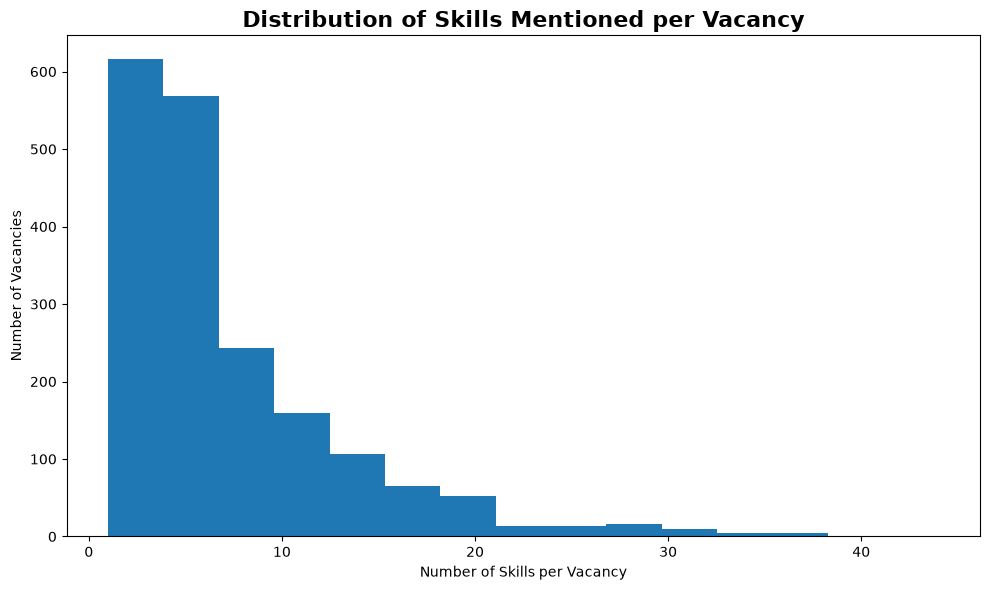

In [24]:
plt.figure(figsize=(10, 6))

plt.hist(
    skills_per_vacancy,
    bins=15
)

plt.title(
    "Distribution of Skills Mentioned per Vacancy",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Skills per Vacancy")
plt.ylabel("Number of Vacancies")

plt.tight_layout()
plt.show()

In [26]:
# Create a vacancy → skill list

vacancy_skill_groups = (
    vacancy_skill_data
    .groupby("vacancy_id")["name"]
    .apply(lambda x: sorted(set(x.dropna())))
)

vacancy_skill_groups.head()

vacancy_id
1    [Agile, Analytical Skills, Data Reporting, ERP...
2    [A/B Testing, Campaign Analysis, Dashboarding,...
3    [AWS, Advanced SQL, Analytical Data Modeling, ...
4    [AWS, AWS Glue, Azure, Data Governance, Data M...
5    [Data Analysis, Data Modeling, Data Visualizat...
Name: name, dtype: object

In [27]:
# Generate skill pairs

from itertools import combinations

skill_pairs = []

for skills_list in vacancy_skill_groups:
    if len(skills_list) >= 2:
        pairs = combinations(skills_list, 2)

        for skill1, skill2 in pairs:
            skill_pairs.append((skill1, skill2))

skill_pairs_df = pd.DataFrame(
    skill_pairs,
    columns=["skill_1", "skill_2"]
)

print("Total skill pairs:", len(skill_pairs_df))

Total skill pairs: 73472


In [28]:
# Count the combinations

skill_pair_counts = (
    skill_pairs_df
    .value_counts()
    .reset_index(name="vacancy_count")
    .sort_values("vacancy_count", ascending=False)
)

skill_pair_counts.head(20)

,skill_1,skill_2,vacancy_count
0,Python,SQL,649
1,SQL,Tableau,579
2,Power BI,SQL,446
3,Excel,SQL,434
4,Python,Tableau,365
5,Python,R,354
6,R,SQL,328
7,Power BI,Tableau,305
8,Power BI,Python,273
9,Excel,Power BI,254


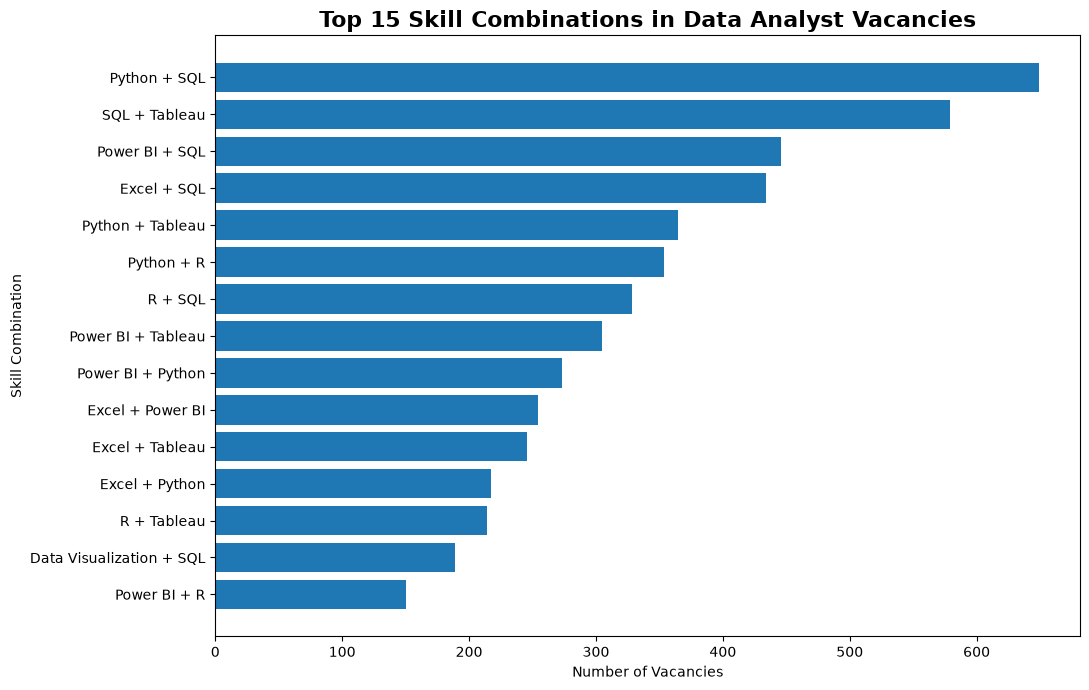

In [29]:
# Visualize the top combinations

top_pairs = skill_pair_counts.head(15).copy()

top_pairs["combination"] = (
    top_pairs["skill_1"]
    + " + "
    + top_pairs["skill_2"]
)

top_pairs = top_pairs.sort_values("vacancy_count")

plt.figure(figsize=(11, 7))

plt.barh(
    top_pairs["combination"],
    top_pairs["vacancy_count"]
)

plt.title(
    "Top 15 Skill Combinations in Data Analyst Vacancies",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Vacancies")
plt.ylabel("Skill Combination")

plt.tight_layout()
plt.show()

In [30]:
# Skills by Experience Level

level_skill_summary = (
    skill_level_analysis
    .sort_values(
        ["experience_level_clean", "vacancy_count"],
        ascending=[True, False]
    )
)

top_skills_by_level = (
    level_skill_summary
    .groupby("experience_level_clean")
    .head(10)
)

top_skills_by_level[
    [
        "experience_level_clean",
        "name",
        "vacancy_count"
    ]
]

,experience_level_clean,name,vacancy_count
149,Associate,SQL,22
59,Associate,Data Visualization,15
167,Associate,Tableau,15
72,Associate,Excel,13
126,Associate,Power BI,13
...,...,...,...
3559,Unknown,Data Modeling,6
3571,Unknown,Data Warehousing,6
3611,Unknown,Python,6
3625,Unknown,Statistics,4


In [31]:
# Entry vs Senior Skill Comparison

entry_skills = (
    skill_level_analysis[
        skill_level_analysis["experience_level_clean"] == "Entry Level"
    ]
    .sort_values("vacancy_count", ascending=False)
    .head(10)
)

senior_skills = (
    skill_level_analysis[
        skill_level_analysis["experience_level_clean"] == "Senior"
    ]
    .sort_values("vacancy_count", ascending=False)
    .head(10)
)

print("ENTRY LEVEL")
display(entry_skills[["name", "vacancy_count"]])

print("\nSENIOR")
display(senior_skills[["name", "vacancy_count"]])

ENTRY LEVEL


,name,vacancy_count
336,Excel,144
493,SQL,134
460,Python,60
448,Power BI,58
527,Tableau,50
260,Data Analysis,31
304,Data Visualization,30
419,Microsoft Excel,30
470,R,24
451,PowerPoint,24



SENIOR


,name,vacancy_count
3377,SQL,187
3327,Python,97
3459,Tableau,85
3298,Power BI,77
3338,R,58
3094,Excel,53
3016,Data Visualization,45
2983,Data Modeling,37
2947,Data Analysis,36
3188,Looker,35


In [32]:
# Skills per Vacancy

average_skills = skills_per_vacancy.mean()
median_skills = skills_per_vacancy.median()
max_skills = skills_per_vacancy.max()

print("Average skills per vacancy:", round(average_skills, 2))
print("Median skills per vacancy:", median_skills)
print("Maximum skills in a vacancy:", max_skills)

Average skills per vacancy: 6.96
Median skills per vacancy: 5.0
Maximum skills in a vacancy: 44


In [33]:
skill_pair_counts.head(20)

,skill_1,skill_2,vacancy_count
0,Python,SQL,649
1,SQL,Tableau,579
2,Power BI,SQL,446
3,Excel,SQL,434
4,Python,Tableau,365
5,Python,R,354
6,R,SQL,328
7,Power BI,Tableau,305
8,Power BI,Python,273
9,Excel,Power BI,254


In [34]:
top_skills_by_level

,experience_level_clean,name,vacancy_count
149,Associate,SQL,22
59,Associate,Data Visualization,15
167,Associate,Tableau,15
72,Associate,Excel,13
126,Associate,Power BI,13
...,...,...,...
3559,Unknown,Data Modeling,6
3571,Unknown,Data Warehousing,6
3611,Unknown,Python,6
3625,Unknown,Statistics,4


In [35]:
display(entry_skills[["name", "vacancy_count"]])
display(senior_skills[["name", "vacancy_count"]])

,name,vacancy_count
336,Excel,144
493,SQL,134
460,Python,60
448,Power BI,58
527,Tableau,50
260,Data Analysis,31
304,Data Visualization,30
419,Microsoft Excel,30
470,R,24
451,PowerPoint,24


,name,vacancy_count
3377,SQL,187
3327,Python,97
3459,Tableau,85
3298,Power BI,77
3338,R,58
3094,Excel,53
3016,Data Visualization,45
2983,Data Modeling,37
2947,Data Analysis,36
3188,Looker,35


In [36]:
print("Average:", round(average_skills, 2))
print("Median:", median_skills)
print("Maximum:", max_skills)

Average: 6.96
Median: 5.0
Maximum: 44


# 🔑 Key Insights

### 1. Job Market Demand
- The dataset contains **2,154 Data Analyst-related vacancies**.
- **Data Analyst** is the most common job category with **1,682 vacancies (~78%)**.
- Senior Data Analyst roles are the second-largest category with **181 vacancies**.

### 2. Most In-Demand Skills
- **SQL** is the most demanded skill, appearing in approximately **69.3%** of vacancies with skill data.
- **Python, Excel, Tableau, and Power BI** are also among the most frequently requested skills.
- This highlights the importance of combining database, programming, spreadsheet, and visualization skills.

### 3. Entry-Level Skill Requirements
- Entry-level positions show the highest demand for **Excel (144)** and **SQL (134)**.
- Python, Power BI, and Tableau are also frequently requested.
- This suggests that strong fundamentals in **Excel and SQL** can provide a solid foundation for entering the Data Analytics field.

### 4. Senior-Level Skill Requirements
- **SQL (187)** is the most demanded skill among senior-level positions.
- Python, Tableau, Power BI, R, and Excel are also highly requested.
- Senior positions therefore tend to require a broader combination of technical, analytical, and visualization skills.

### 5. Skill Combination Analysis
- **Power BI + Python**, **Excel + Power BI**, and **Excel + Tableau** are among the most common skill combinations.
- Other strong combinations include SQL with Data Visualization, Data Modeling, Looker, and SAS.
- Employers frequently seek **combinations of complementary skills rather than a single technology**.

### 6. Skills Required per Vacancy
- A vacancy mentions an average of approximately **6.96 skills**.
- The median number of skills is **5**, while the maximum is **44**.
- This indicates that Data Analyst roles generally require a **multi-skill profile**.

### 7. Location Insights
- The dataset contains **777 unique location values**.
- Major job locations include **Anywhere, United States, New York, Kuala Lumpur, Singapore, and San Francisco**.
- Opportunities are distributed across multiple countries and regions.

### 8. Remote Work Demand
- Location-specific/onsite vacancies significantly outnumber remote vacancies.
- Remote opportunities are present but represent a smaller share of the collected job market.
- This suggests that candidates should remain open to both **remote and location-based opportunities**.

---

# 🎯 Overall Conclusion

The analysis shows that **SQL is the core skill for Data Analyst roles**, while Python, Excel, Tableau, and Power BI provide important complementary capabilities. Entry-level positions emphasize foundational skills such as Excel and SQL, while senior positions demand a broader technical and analytical skill set. The high number of skills mentioned per vacancy also indicates that employers increasingly value **versatile candidates with multiple data analytics capabilities**.